# Retail Sales Performance Analysis and Revenue Prediction Using Python and Machine Learning

## 1. Introduction

Retail businesses generate transaction data that can be used to understand customer purchasing patterns, product category performance, and revenue trends. Analyzing this data helps businesses make informed decisions about sales and business performance.

This project aims to analyze retail transaction data using Python, identify meaningful patterns through exploratory data analysis, and evaluate the feasibility of predicting revenue using machine learning.

## 2. Objectives

- Inspect and validate the retail sales dataset.
- Clean and preprocess data where necessary.
- Analyze revenue patterns across dates, product categories, and customer demographics.
- Create meaningful visualizations to communicate business insights.
- Develop and evaluate a suitable revenue prediction model, provided the dataset supports reliable evaluation.
- Present findings and recommendations in a structured project report.

## 3. Tools and Technologies

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, and Jupyter Notebook in Visual Studio Code.

In [1]:
# Cell 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Set the visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load the dataset from the project folder
DATA_PATH = Path.cwd() / "retail_sales_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 1000
Number of columns: 9


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
# Phase 2: Data Quality Assessment

print("Dataset Shape:", df.shape)

# 1. Check missing values
print("\n--- Missing Values ---")
display(df.isnull().sum().to_frame("Missing Values"))

# 2. Check duplicate rows
print("\n--- Duplicate Records ---")
print("Duplicate rows:", df.duplicated().sum())

# 3. Check data types
print("\n--- Data Types ---")
display(df.dtypes.to_frame("Data Type"))

# 4. Check unique values in categorical columns
print("\n--- Product Categories ---")
print(df["Product Category"].value_counts())

print("\n--- Gender Distribution ---")
print(df["Gender"].value_counts())

# 5. Check date range
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("\n--- Date Range ---")
print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())

# 6. Check numerical values
print("\n--- Numerical Summary ---")
display(df[["Age", "Quantity", "Price per Unit", "Total Amount"]].describe())

Dataset Shape: (1000, 9)

--- Missing Values ---


,Missing Values
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0



--- Duplicate Records ---
Duplicate rows: 0

--- Data Types ---


,Data Type
Transaction ID,int64
Date,str
Customer ID,str
Gender,str
Age,int64
Product Category,str
Quantity,int64
Price per Unit,int64
Total Amount,int64



--- Product Categories ---
Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

--- Gender Distribution ---
Gender
Female    510
Male      490
Name: count, dtype: int64

--- Date Range ---
Earliest date: 2023-01-01 00:00:00
Latest date: 2024-01-01 00:00:00

--- Numerical Summary ---


,Age,Quantity,Price per Unit,Total Amount
count,1000.00000,1000.000000,1000.000000,1000.000000
mean,41.39200,2.514000,179.890000,456.000000
std,13.68143,1.132734,189.681356,559.997632
min,18.00000,1.000000,25.000000,25.000000
25%,29.00000,1.000000,30.000000,60.000000
50%,42.00000,3.000000,50.000000,135.000000
75%,53.00000,4.000000,300.000000,900.000000
max,64.00000,4.000000,500.000000,2000.000000


In [4]:
# Revenue validation

expected_amount = df["Quantity"] * df["Price per Unit"]

mismatch_count = (
    ~np.isclose(
        expected_amount,
        df["Total Amount"],
        rtol=1e-9,
        atol=1e-6,
        equal_nan=False
    )
).sum()

print("Revenue mismatches:", mismatch_count)

if mismatch_count == 0:
    print("All transaction amounts match Quantity × Price per Unit.")
else:
    print("Some transactions require investigation.")
    display(
        df.loc[
            ~np.isclose(
                expected_amount,
                df["Total Amount"],
                rtol=1e-9,
                atol=1e-6,
                equal_nan=False
            ),
            ["Transaction ID", "Quantity", "Price per Unit", "Total Amount"]
        ].head(10)
    )

Revenue mismatches: 0
All transaction amounts match Quantity × Price per Unit.


In [5]:
# Phase 2: Data Cleaning

df_clean = df.copy()

# Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.replace(" ", "_")
)

# Remove exact duplicate rows, if any
df_clean = df_clean.drop_duplicates().copy()

# Standardize text categories
for col in ["Gender", "Product_Category"]:
    df_clean[col] = df_clean[col].astype("string").str.strip().str.title()

# Convert dates and numerical columns
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"], errors="coerce"
)

numeric_cols = [
    "Age", "Quantity", "Price_per_Unit", "Total_Amount"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Missing values after standardization:")
display(df_clean.isnull().sum().to_frame("Missing Values"))

Original rows: 1000
Cleaned rows: 1000
Missing values after standardization:


,Missing Values
Transaction_ID,0
Date,0
Customer_ID,0
Gender,0
Age,0
Product_Category,0
Quantity,0
Price_per_Unit,0
Total_Amount,0


In [6]:
# Phase 3: Prepare data for analysis

# Work with the cleaned dataset
analysis_df = df_clean.copy()

# Keep records with valid dates and values
analysis_df = analysis_df.dropna(
    subset=["Date", "Quantity", "Price_per_Unit", "Total_Amount"]
).copy()

# Create useful time-based columns
analysis_df["Year_Month"] = analysis_df["Date"].dt.to_period("M").astype(str)
analysis_df["Month"] = analysis_df["Date"].dt.month_name()
analysis_df["Day"] = analysis_df["Date"].dt.day

# Verify the data
print("Records available for analysis:", len(analysis_df))
print("Date range:",
      analysis_df["Date"].min().date(),
      "to",
      analysis_df["Date"].max().date())

print("\nTotal revenue:", round(analysis_df["Total_Amount"].sum(), 2))
print("Total transactions:", analysis_df["Transaction_ID"].nunique())

Records available for analysis: 1000
Date range: 2023-01-01 to 2024-01-01

Total revenue: 456000
Total transactions: 1000


NameError: name 'OUTPUT_DIR' is not defined

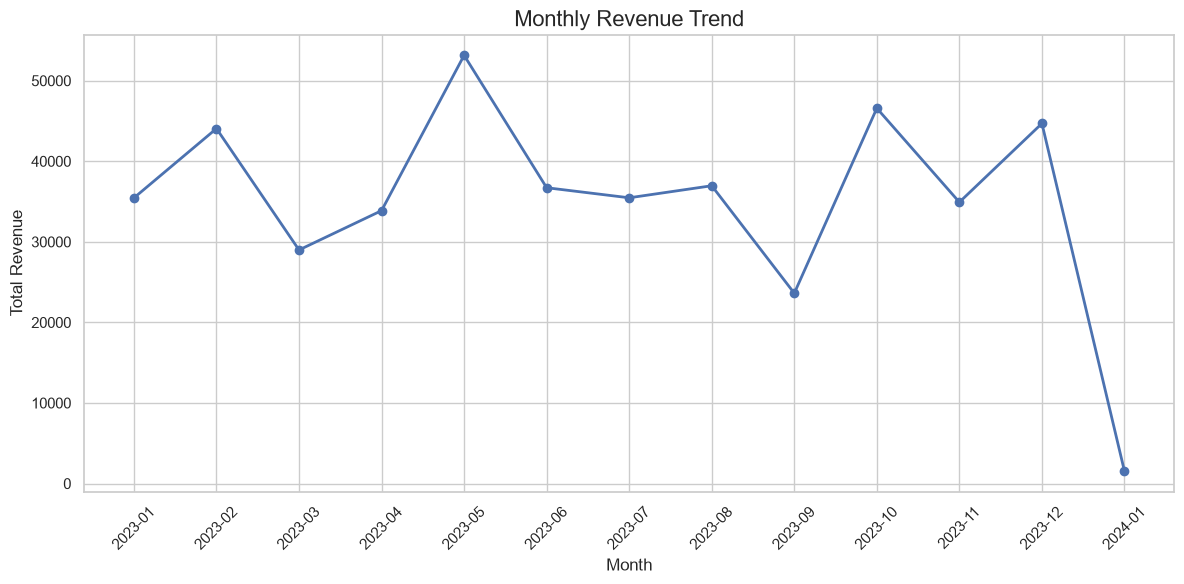

In [7]:
# Graph 1: Monthly Revenue Trend

monthly_revenue = (
    analysis_df.groupby("Year_Month")["Total_Amount"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "01_monthly_revenue.png", dpi=300)
plt.show()

display(monthly_revenue.to_frame("Revenue"))

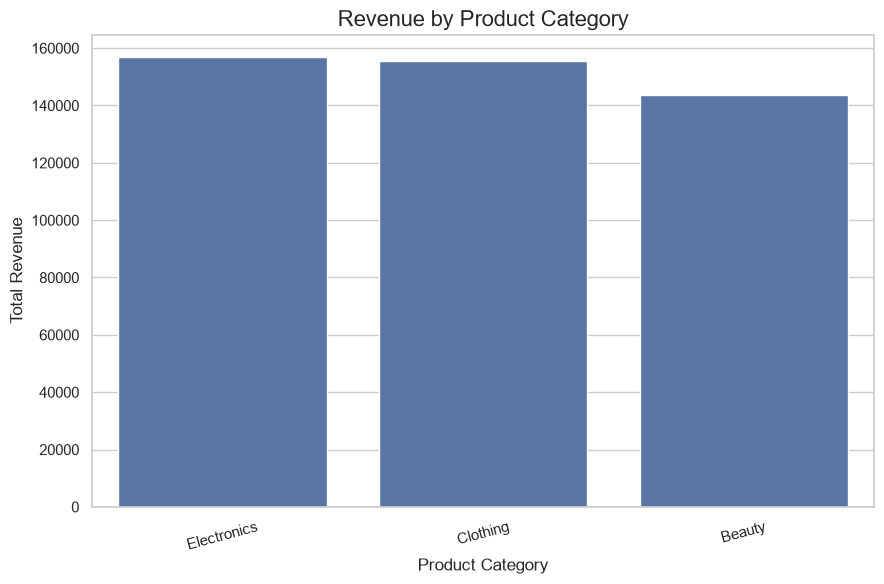

,Revenue
Product_Category,
Electronics,156905
Clothing,155580
Beauty,143515


In [ ]:
# Graph 2: Revenue by Product Category

category_revenue = (
    analysis_df.groupby("Product_Category")["Total_Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values
)

plt.title("Revenue by Product Category", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "02_category_revenue.png", dpi=300)
plt.show()

display(category_revenue.to_frame("Revenue"))

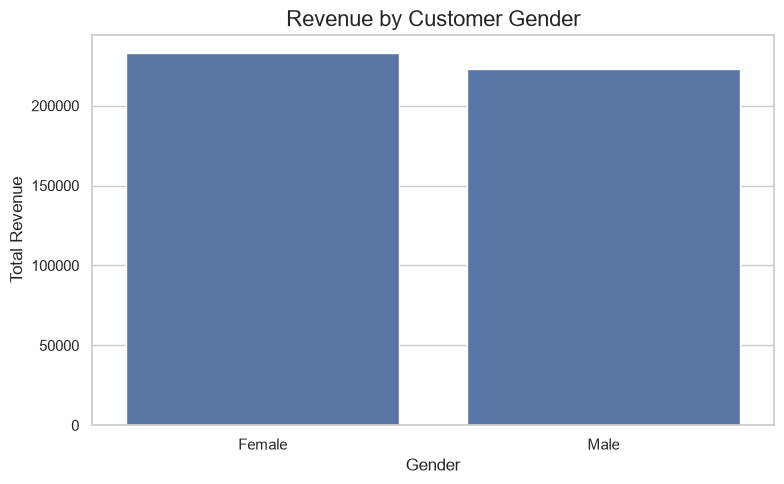

,Revenue
Gender,
Female,232840
Male,223160


In [ ]:
# Graph 3: Revenue by Gender

gender_revenue = (
    analysis_df.groupby("Gender")["Total_Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=gender_revenue.index,
    y=gender_revenue.values
)

plt.title("Revenue by Customer Gender", fontsize=16)
plt.xlabel("Gender")
plt.ylabel("Total Revenue")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "03_gender_revenue.png", dpi=300)
plt.show()

display(gender_revenue.to_frame("Revenue"))

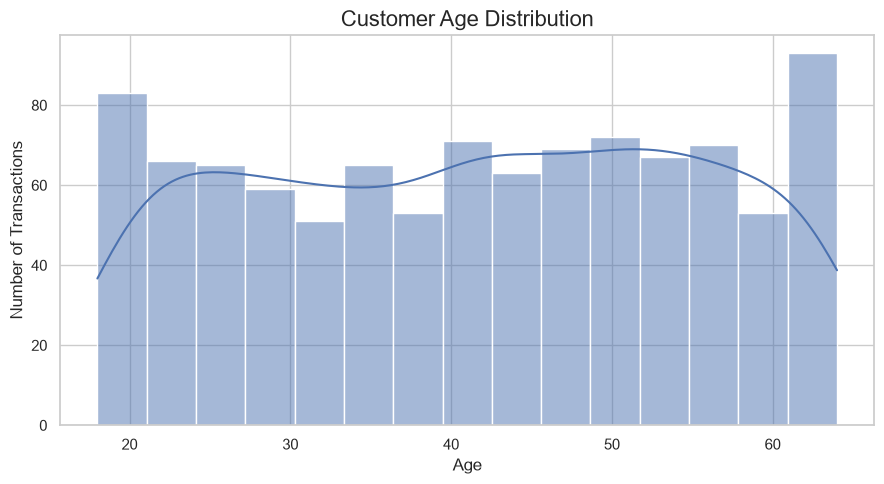

In [ ]:
# Graph 4: Customer Age Distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    data=analysis_df,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Customer Age Distribution", fontsize=16)
plt.xlabel("Age")
plt.ylabel("Number of Transactions")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "04_customer_age_distribution.png", dpi=300)
plt.show()

In [ ]:
# Key Business Insights

total_revenue = analysis_df["Total_Amount"].sum()

top_category = category_revenue.idxmax()
top_category_revenue = category_revenue.max()

top_gender = gender_revenue.idxmax()
top_gender_revenue = gender_revenue.max()

best_month = monthly_revenue.idxmax()
best_month_revenue = monthly_revenue.max()

print("========== BUSINESS INSIGHTS ==========")

print(f"Total revenue: {total_revenue:,.2f}")

print(
    f"Top revenue-generating category: {top_category} "
    f"({top_category_revenue:,.2f})"
)

print(
    f"Highest-revenue gender group: {top_gender} "
    f"({top_gender_revenue:,.2f})"
)

print(
    f"Highest-revenue month: {best_month} "
    f"({best_month_revenue:,.2f})"
)

print("\nMonthly revenue summary:")
display(monthly_revenue.describe().to_frame("Value"))

========== BUSINESS INSIGHTS ==========
Total revenue: 456,000.00
Top revenue-generating category: Electronics (156,905.00)
Highest-revenue gender group: Female (232,840.00)
Highest-revenue month: 2023-05 (53,150.00)

Monthly revenue summary:


,Value
count,13.000000
mean,35076.923077
std,12694.394849
min,1530.000000
25%,33870.000000
50%,35465.000000
75%,44060.000000
max,53150.000000


In [ ]:
# Phase 4: Prepare daily revenue data

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Aggregate transaction revenue by date
daily_revenue = (
    analysis_df.groupby("Date")["Total_Amount"]
    .sum()
    .sort_index()
)

# Create a continuous daily date index
# Assumption: dates without recorded transactions represent zero sales.
full_dates = pd.date_range(
    daily_revenue.index.min(),
    daily_revenue.index.max(),
    freq="D"
)

daily_revenue = daily_revenue.reindex(
    full_dates, fill_value=0
)
daily_revenue.index.name = "Date"
daily_revenue.name = "Revenue"

print("Daily observations:", len(daily_revenue))
print("Start date:", daily_revenue.index.min().date())
print("End date:", daily_revenue.index.max().date())

display(daily_revenue.head())

Daily observations: 366
Start date: 2023-01-01
End date: 2024-01-01


Date
2023-01-01    3600
2023-01-02    1765
2023-01-03     600
2023-01-04    1240
2023-01-05    1100
Freq: D, Name: Revenue, dtype: int64

In [ ]:
# Create calendar and historical revenue features

model_data = daily_revenue.to_frame().copy()

model_data["DayOfWeek"] = model_data.index.dayofweek
model_data["Month"] = model_data.index.month
model_data["DayOfYear"] = model_data.index.dayofyear
model_data["IsWeekend"] = (
    model_data["DayOfWeek"] >= 5
).astype(int)

# Historical revenue features; shift prevents using today's target
model_data["Lag_1"] = model_data["Revenue"].shift(1)
model_data["Lag_7"] = model_data["Revenue"].shift(7)

model_data["Rolling_Mean_7"] = (
    model_data["Revenue"].shift(1).rolling(7).mean()
)

model_data = model_data.dropna()

features = [
    "DayOfWeek",
    "Month",
    "DayOfYear",
    "IsWeekend",
    "Lag_1",
    "Lag_7",
    "Rolling_Mean_7"
]

X = model_data[features]
y = model_data["Revenue"]

print("Modeling observations:", len(model_data))
display(model_data.head())

Modeling observations: 359


,Revenue,DayOfWeek,Month,DayOfYear,IsWeekend,Lag_1,Lag_7,Rolling_Mean_7
Date,,,,,,,,
2023-01-08,625,6,1,8,1,150.0,3600.0,1296.428571
2023-01-09,200,0,1,9,0,625.0,1765.0,871.428571
2023-01-10,230,1,1,10,0,200.0,600.0,647.857143
2023-01-11,280,2,1,11,0,230.0,1240.0,595.000000
2023-01-12,0,3,1,12,0,280.0,1100.0,457.857143


In [ ]:
# Chronological 80/20 split

split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Test period:", X_test.index.min().date(),
      "to", X_test.index.max().date())

Training observations: 287
Testing observations: 72
Test period: 2023-10-22 to 2024-01-01


In [ ]:
# Train models

models = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=6,
        min_samples_leaf=3,
        random_state=42
    )
}

predictions = {}
results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    # Revenue cannot be negative
    pred = np.maximum(pred, 0)

    predictions[name] = pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("MAE")

display(results_df.round(3))

,Model,MAE,RMSE,R2
0,Baseline,802.322,1002.121,-0.017
2,Random Forest,832.145,1042.736,-0.101
1,Linear Regression,844.150,1055.435,-0.128


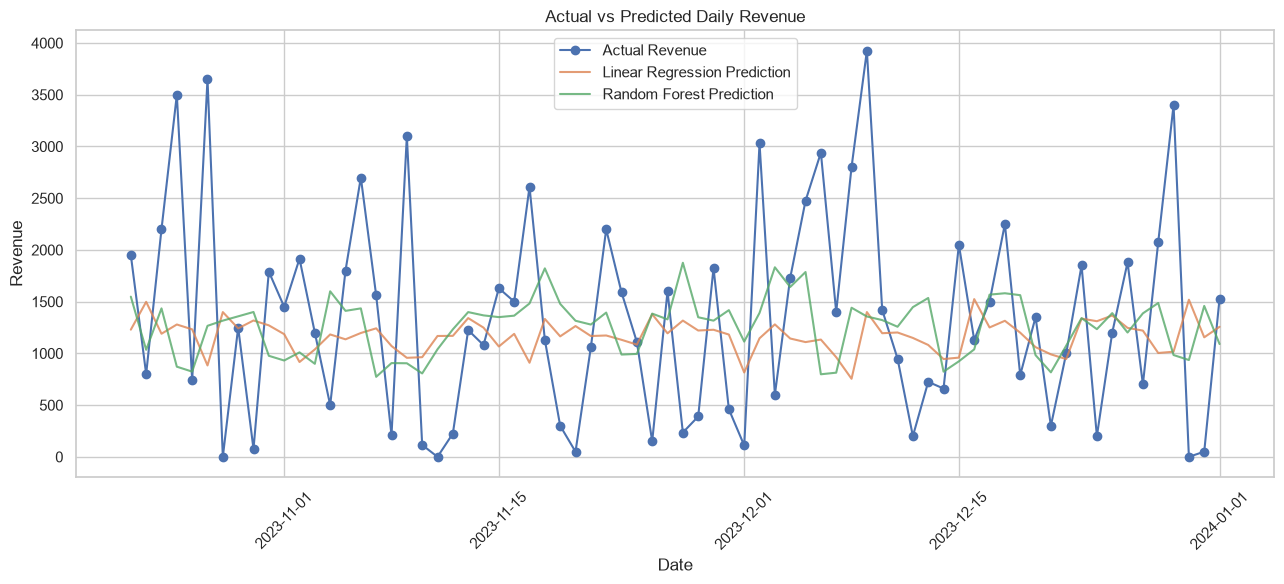

In [ ]:
# Plot test-period predictions

plt.figure(figsize=(13, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual Revenue",
    marker="o"
)

for name, pred in predictions.items():
    if name != "Baseline":
        plt.plot(
            y_test.index,
            pred,
            label=f"{name} Prediction",
            alpha=0.8
        )

plt.title("Actual vs Predicted Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "05_actual_vs_predicted_revenue.png",
    dpi=300
)

plt.show()

In [ ]:
# Save evaluation results and test predictions

results_df.to_csv(
    OUTPUT_DIR / "model_evaluation_results.csv",
    index=False
)

prediction_df = pd.DataFrame(
    {"Actual_Revenue": y_test}
)

for name, pred in predictions.items():
    prediction_df[f"{name}_Prediction"] = pred

prediction_df.to_csv(
    OUTPUT_DIR / "revenue_predictions.csv"
)

print("Model results and predictions saved in:", OUTPUT_DIR)

Model results and predictions saved in: c:\Users\albin aby\OneDrive\ドキュメント\Retail_Revenue_Project\outputs


In [ ]:
from docx import Document
from docx.shared import Inches, Pt
from pathlib import Path
import pandas as pd
import numpy as np

# Create the Word report
report = Document()

report.add_heading(
    "Retail Sales Performance Analysis and Revenue Prediction",
    level=0
)
report.add_paragraph(
    "IBM SkillsBuild Data Analytics with AI Academic Internship"
)
report.add_paragraph("Prepared by: Alen Aby")

report.add_heading("1. Introduction", level=1)
report.add_paragraph(
    "This project analyzes retail transaction data using Python. "
    "It applies data validation, exploratory data analysis, "
    "visualization and machine-learning techniques to investigate "
    "revenue patterns and evaluate daily revenue prediction."
)

report.add_heading("2. Project Objectives", level=1)
for objective in [
    "Inspect and validate the retail sales dataset.",
    "Prepare data for reliable analysis.",
    "Analyze revenue trends and customer purchasing patterns.",
    "Visualize revenue by month, category and gender.",
    "Compare regression models using a chronological test split.",
    "Communicate findings and limitations."
]:
    report.add_paragraph(objective, style="List Bullet")

report.add_heading("3. Tools and Technologies", level=1)
report.add_paragraph(
    "Python, Pandas, NumPy, Matplotlib, Seaborn, "
    "Scikit-learn, Jupyter Notebook and Visual Studio Code."
)

report.add_heading("4. Dataset Description", level=1)
report.add_paragraph(
    f"The dataset contains {len(df):,} rows and {len(df.columns)} columns. "
    "The available fields include transaction ID, date, customer ID, "
    "gender, age, product category, quantity, price per unit and total amount."
)
report.add_paragraph(
    "Revenue was analyzed using the Total Amount field. "
    "The transaction amount was also checked against quantity multiplied "
    "by price per unit."
)

report.add_heading("5. Data Cleaning and Validation", level=1)
report.add_paragraph(
    f"Exact duplicate rows in the original dataset: "
    f"{df.duplicated().sum():,}."
)
report.add_paragraph(
    "Data types, missing values, category consistency, date validity "
    "and revenue calculations were examined before analysis. "
    "Any assumptions or limitations identified during these checks "
    "should be considered when interpreting the findings."
)

report.add_heading("6. Exploratory Data Analysis", level=1)

chart_files = [
    ("01_monthly_revenue.png", "Figure 1. Monthly Revenue Trend"),
    ("02_category_revenue.png", "Figure 2. Revenue by Product Category"),
    ("03_gender_revenue.png", "Figure 3. Revenue by Customer Gender"),
    ("04_customer_age_distribution.png", "Figure 4. Customer Age Distribution"),
    ("05_actual_vs_predicted_revenue.png",
     "Figure 5. Actual vs Predicted Daily Revenue")
]

for filename, caption in chart_files:
    path = OUTPUT_DIR / filename
    if path.exists():
        report.add_paragraph(caption)
        report.add_picture(str(path), width=Inches(6.0))

report.add_heading("7. Revenue Prediction Methodology", level=1)
report.add_paragraph(
    "Daily revenue was calculated by aggregating transaction amounts "
    "by date. Calendar variables and lagged revenue features were prepared. "
    "The data was split chronologically into training and testing periods "
    "to avoid randomly mixing future observations into the training set."
)
report.add_paragraph(
    "A mean-prediction baseline, Linear Regression and Random Forest "
    "Regressor were compared. Model performance was evaluated using "
    "Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and R-squared."
)

report.add_heading("8. Model Evaluation Results", level=1)

if "results_df" in globals() and not results_df.empty:
    table = report.add_table(rows=1, cols=len(results_df.columns))
    table.style = "Light Shading Accent 1"

    for i, col in enumerate(results_df.columns):
        table.rows[0].cells[i].text = str(col)

    for _, row in results_df.iterrows():
        cells = table.add_row().cells
        for i, value in enumerate(row):
            cells[i].text = (
                f"{value:.4f}" if isinstance(value, (int, float, np.number))
                else str(value)
            )

    report.add_paragraph(
        "The best-performing model should be selected based on its "
        "test-set performance relative to the baseline. Lower MAE and RMSE "
        "indicate smaller prediction errors; R-squared should be interpreted "
        "alongside these metrics."
    )
else:
    report.add_paragraph(
        "Model evaluation results were not found in the notebook session. "
        "Run the model evaluation cells before generating the final report."
    )

report.add_heading("9. Business Insights and Recommendations", level=1)

if "category_revenue" in globals() and not category_revenue.empty:
    report.add_paragraph(
        f"The highest-revenue category in the analyzed data was "
        f"{category_revenue.idxmax()}, with revenue of "
        f"{category_revenue.max():,.2f}."
    )

if "monthly_revenue" in globals() and not monthly_revenue.empty:
    report.add_paragraph(
        f"The highest-revenue month in the analysis was "
        f"{monthly_revenue.idxmax()}, with revenue of "
        f"{monthly_revenue.max():,.2f}."
    )

report.add_paragraph(
    "Businesses can use these results to investigate category performance, "
    "review sales trends and support planning. Recommendations should be "
    "based on the actual charts and model results."
)

report.add_heading("10. Limitations", level=1)
report.add_paragraph(
    "The dataset contains a limited historical period and transaction "
    "records rather than a verified complete daily sales series. Dates "
    "without transactions may not necessarily represent zero sales. "
    "The forecasting results are exploratory and should not be treated "
    "as reliable future forecasts without further validation on additional "
    "historical data."
)

report.add_heading("11. Conclusion", level=1)
report.add_paragraph(
    "This project demonstrates a complete introductory analytics workflow, "
    "from data validation and visualization to machine-learning evaluation. "
    "The findings and model metrics provide a basis for understanding "
    "retail revenue patterns while highlighting the importance of data "
    "quality and appropriate model validation."
)

report_path = PROJECT_DIR / "AlenAby_ProjectReport.docx"
report.save(report_path)

print("Word report created:", report_path.resolve())

Word report created: C:\Users\albin aby\OneDrive\ドキュメント\Retail_Revenue_Project\AlenAby_ProjectReport.docx
